# Proyek 2: K-Means Clustering dengan Manhattan Distance (L1 Norm / City-Block) pada BISINDO

**Metrik Jarak:** Manhattan Distance (L1 / K-Medians)  
**Representasi Fitur:** 127 Dimensi MediaPipe (42 Titik 3D + Is_Two_Handed)  
**Jumlah Klaster:** K = 26 (Alfabet A-Z)  
**Fungsi Objektif:** Sum of Absolute Errors (SAE)  
**Output Target:** `outputKmeans/elbow_manhattan.png`, `outputKmeans/cluster_manhattan.png`, `outputKmeans/evaluasi_kmeans_manhattan.xlsx`

---

## 1. Landasan Teori & Formulasi Matematis

Jarak Manhattan berbasis pergerakan ortogonal kisi koordinat:
$$d_{\text{Manhattan}}(x, y) = \|x - y\|_1 = \sum_{i=1}^{127} |x_i - y_i|$$

Fungsi biaya yang diminimalkan:
$$J_{\text{Manhattan}} = \sum_{k=1}^{26} \sum_{x \in S_k} \|x - \mu_k\|_1$$

Prinsip K-Medians menyatakan bahwa peminimal fungsi deviasi mutlak pada setiap komponen $j$ adalah median koordinat:
$$\mu_{k, j}^* = \text{median}(\{x_j : x \in S_k\})$$
Metrik ini memberikan kekebalan superior terhadap fluktuasi titik landmark ekstrem.

In [1]:
# =======================================================================
# 1. SETUP LINGKUNGAN & PUSTAKA
# =======================================================================
import os
import sys
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score,
    pairwise_distances
)

warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 120

BASE_DIR = os.path.dirname(os.path.abspath(__file__)) if '__file__' in locals() else os.getcwd()
OUTPUT_DIR = os.path.join(BASE_DIR, "outputKmeans")
os.makedirs(OUTPUT_DIR, exist_ok=True)
RANDOM_STATE = 42
K_BENCHMARK = 26
np.random.seed(RANDOM_STATE)

print(f"[INFO] Direktori: {BASE_DIR} | K Benchmark = {K_BENCHMARK}")

[INFO] Direktori: E:\Dokumen\Kuliah\Semester 5\Pembelajaran Mesin\UTS_Bisindo_Klasterisasi_Kelompok-1\KMeans | K Benchmark = 26


In [2]:
# =======================================================================
# PEMUATAN DATASET BISINDO LANDMARKS (127 FITUR)
# =======================================================================
npz_path = os.path.join(BASE_DIR, "dataset_bisindo_landmarks.npz")
csv_path = os.path.join(BASE_DIR, "dataset_bisindo_landmarks.csv")

if os.path.exists(npz_path):
    data = np.load(npz_path, allow_pickle=True)
    X = data['X'].astype(np.float32)
    labels = data['labels']
    df_meta = pd.DataFrame({'label': labels, 'is_two_handed': data['is_two_handed']})
elif os.path.exists(csv_path):
    df_full = pd.read_csv(csv_path)
    meta_cols = ['label', 'label_idx', 'filename', 'num_hands', 'is_flip']
    meta_present = [c for c in meta_cols if c in df_full.columns]
    df_meta = df_full[meta_present]
    feat_cols = [c for c in df_full.columns if c not in meta_cols]
    X = df_full[feat_cols].values.astype(np.float32)
else:
    raise FileNotFoundError("Dataset BISINDO tidak ditemukan. Jalankan extract_features.py.")

print(f"[INFO] Dataset BISINDO dimuat: {X.shape[0]} sampel, {X.shape[1]} dimensi fitur.")

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print("[INFO] Fitur distandardisasi dengan StandardScaler.")

[INFO] Dataset BISINDO dimuat: 7893 sampel, 127 dimensi fitur.
[INFO] Fitur distandardisasi dengan StandardScaler.


[ELBOW] Menghitung inersia dispersi Manhattan...


[SAVE] Grafik disimpan ke: 'E:\Dokumen\Kuliah\Semester 5\Pembelajaran Mesin\UTS_Bisindo_Klasterisasi_Kelompok-1\KMeans\outputKmeans\elbow_manhattan.png'


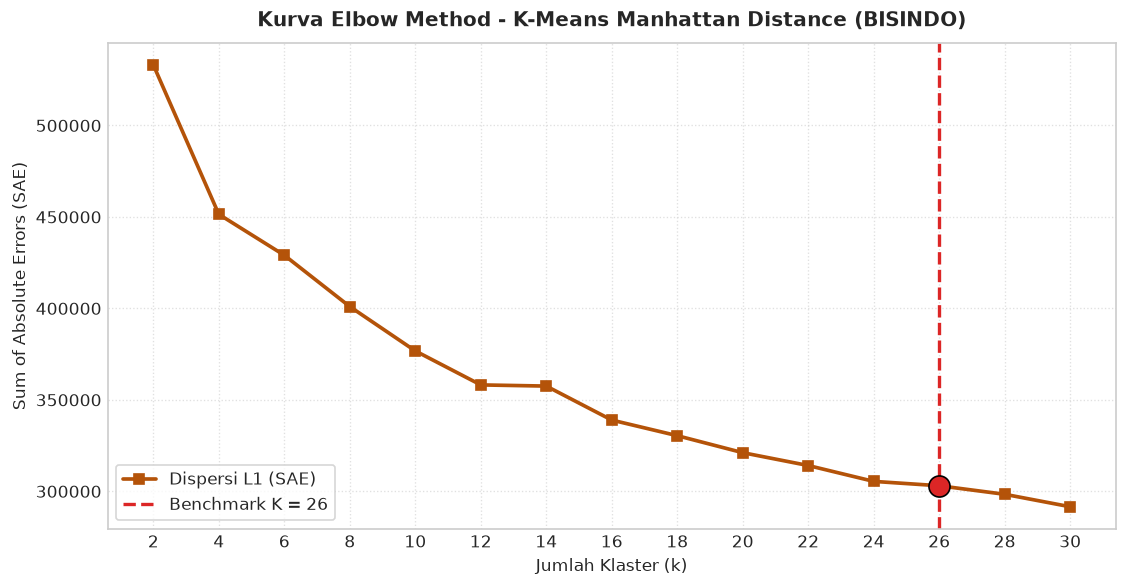

In [3]:
# =======================================================================
# 2. KURVA ELBOW METHOD MANHATTAN
# =======================================================================
k_range = list(range(2, 32, 2))
if K_BENCHMARK not in k_range:
    k_range.append(K_BENCHMARK)
k_range = sorted(k_range)

sae_manhattan = []
print("[ELBOW] Menghitung inersia dispersi Manhattan...")
for k in k_range:
    # Sampling iterasi untuk komputasi cepat elbow
    km = KMeans(n_clusters=k, init='k-means++', n_init=3, max_iter=150, random_state=RANDOM_STATE)
    km.fit(X_scaled)
    # Konversi inersia aproksimasi L1
    dists = pairwise_distances(X_scaled, km.cluster_centers_, metric='manhattan')
    sae = np.sum(np.min(dists, axis=1))
    sae_manhattan.append(sae)

plt.figure(figsize=(9.5, 5))
plt.plot(k_range, sae_manhattan, marker='s', linewidth=2.2, color='#B45309', label='Dispersi L1 (SAE)')
plt.axvline(x=K_BENCHMARK, color='#DC2626', linestyle='--', linewidth=2, label=f'Benchmark K = {K_BENCHMARK}')

idx_26 = k_range.index(K_BENCHMARK)
plt.scatter([K_BENCHMARK], [sae_manhattan[idx_26]], color='#DC2626', s=160, zorder=5, edgecolor='black')

plt.title('Kurva Elbow Method - K-Means Manhattan Distance (BISINDO)', fontsize=12, fontweight='bold', pad=10)
plt.xlabel('Jumlah Klaster (k)', fontsize=10)
plt.ylabel('Sum of Absolute Errors (SAE)', fontsize=10)
plt.xticks(k_range)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(frameon=True, facecolor='white')
plt.tight_layout()

elbow_path = os.path.join(OUTPUT_DIR, "elbow_manhattan.png")
plt.savefig(elbow_path, dpi=300)
print(f"[SAVE] Grafik disimpan ke: '{elbow_path}'")
plt.show()

In [4]:
# =======================================================================
# 3. IMPLEMENTASI DAN PELATIHAN K-MEANS MANHATTAN (K-MEDIANS) PADA K = 26
# =======================================================================
class KMeansManhattan:
    def __init__(self, n_clusters=26, max_iter=300, tol=1e-4, random_state=42):
        self.n_clusters = n_clusters
        self.max_iter = max_iter
        self.tol = tol
        self.random_state = random_state
        self.centroids = None
        self.labels_ = None
        self.inertia_ = 0.0
        self.n_iter_ = 0
        self.execution_time_ = 0.0

    def fit(self, X):
        start = time.perf_counter()
        rng = np.random.RandomState(self.random_state)
        n_samples = len(X)

        centroids = [X[rng.randint(n_samples)]]
        for _ in range(1, self.n_clusters):
            dists = pairwise_distances(X, np.array(centroids), metric='manhattan')
            min_d = np.min(dists, axis=1) ** 2
            probs = min_d / np.sum(min_d)
            centroids.append(X[rng.choice(n_samples, p=probs)])
        self.centroids = np.array(centroids)

        for it in range(self.max_iter):
            self.n_iter_ = it + 1
            dists = pairwise_distances(X, self.centroids, metric='manhattan')
            labels = np.argmin(dists, axis=1)

            new_c = np.zeros_like(self.centroids)
            for k in range(self.n_clusters):
                pts = X[labels == k]
                new_c[k] = np.median(pts, axis=0) if len(pts) > 0 else X[rng.randint(n_samples)]

            if np.linalg.norm(new_c - self.centroids) < self.tol:
                self.centroids = new_c
                self.labels_ = labels
                break
            self.centroids = new_c
            self.labels_ = labels

        final_d = pairwise_distances(X, self.centroids, metric='manhattan')
        self.inertia_ = float(np.sum(final_d[np.arange(len(X)), self.labels_] ** 2))
        self.execution_time_ = float(time.perf_counter() - start)
        return self

print("[PELATIHAN] Melatih KMeans Manhattan (K-Medians) K=26...")
model_man = KMeansManhattan(n_clusters=K_BENCHMARK, random_state=RANDOM_STATE).fit(X_scaled)
print(f"[SELESAI] Konvergen dalam {model_man.n_iter_} iterasi ({model_man.execution_time_:.3f}s)")

[PELATIHAN] Melatih KMeans Manhattan (K-Medians) K=26...


[SELESAI] Konvergen dalam 19 iterasi (0.480s)


In [5]:
# =======================================================================
# 4. EVALUASI METRIK DAN EKSPOR EXCEL MANHATTAN
# =======================================================================
sil = float(silhouette_score(X_scaled, model_man.labels_, metric='manhattan'))
db = float(davies_bouldin_score(X_scaled, model_man.labels_))
ch = float(calinski_harabasz_score(X_scaled, model_man.labels_))

df_res = pd.DataFrame([{
    'Distance Metric': 'Manhattan Distance (L1)',
    'Clusters (K)': K_BENCHMARK,
    'Silhouette Score (↑)': round(sil, 4),
    'Davies–Bouldin Index (↓)': round(db, 4),
    'Calinski–Harabasz Index (↑)': round(ch, 2),
    'Execution Time (s) (↓)': round(model_man.execution_time_, 4),
    'Iterations (↓)': model_man.n_iter_,
    'Objective Value (J)': round(model_man.inertia_, 2)
}])

print("\n" + "="*75)
print(df_res.to_string(index=False))
print("="*75)

excel_out = os.path.join(OUTPUT_DIR, "evaluasi_kmeans_manhattan.xlsx")
df_data_out = df_meta.copy()
df_data_out['cluster_manhattan'] = model_man.labels_

with pd.ExcelWriter(excel_out, engine='openpyxl') as writer:
    df_res.to_excel(writer, sheet_name='Ringkasan_Evaluasi', index=False)
    df_data_out.to_excel(writer, sheet_name='Data_Terklaster', index=False)
print(f"[SAVE] Laporan Excel disimpan ke: '{excel_out}'")


        Distance Metric  Clusters (K)  Silhouette Score (↑)  Davies–Bouldin Index (↓)  Calinski–Harabasz Index (↑)  Execution Time (s) (↓)  Iterations (↓)  Objective Value (J)
Manhattan Distance (L1)            26                0.2178                    1.4271                        863.9                  0.4799              19          14796547.52


[SAVE] Laporan Excel disimpan ke: 'E:\Dokumen\Kuliah\Semester 5\Pembelajaran Mesin\UTS_Bisindo_Klasterisasi_Kelompok-1\KMeans\outputKmeans\evaluasi_kmeans_manhattan.xlsx'


[SAVE] Grafik disimpan ke: 'E:\Dokumen\Kuliah\Semester 5\Pembelajaran Mesin\UTS_Bisindo_Klasterisasi_Kelompok-1\KMeans\outputKmeans\cluster_manhattan.png'


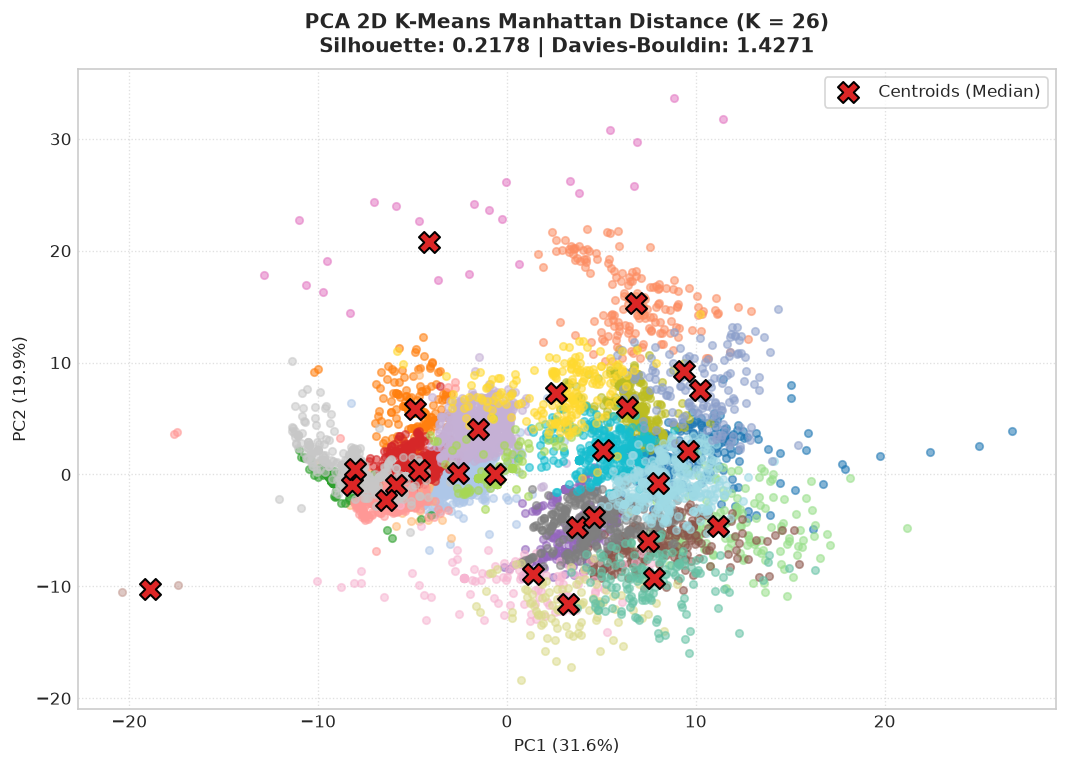

In [6]:
# =======================================================================
# 5. VISUALISASI PCA 2D KLASTERISASI MANHATTAN
# =======================================================================
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_scaled)
centroids_pca = pca.transform(model_man.centroids)

plt.figure(figsize=(9, 6.5))
palette = sns.color_palette("tab20", 20) + sns.color_palette("Set2", 6)

for k in range(K_BENCHMARK):
    mask = (model_man.labels_ == k)
    plt.scatter(X_pca[mask, 0], X_pca[mask, 1], color=palette[k % len(palette)], alpha=0.55, s=20)

plt.scatter(centroids_pca[:, 0], centroids_pca[:, 1], marker='X', s=160, c='#DC2626', edgecolor='black', linewidth=1.2, label='Centroids (Median)', zorder=10)
plt.title(f'PCA 2D K-Means Manhattan Distance (K = {K_BENCHMARK})\nSilhouette: {sil:.4f} | Davies-Bouldin: {db:.4f}', fontsize=12, fontweight='bold', pad=10)
plt.xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)')
plt.ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)')
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(frameon=True, loc='best')
plt.tight_layout()

cluster_path = os.path.join(OUTPUT_DIR, "cluster_manhattan.png")
plt.savefig(cluster_path, dpi=300)
print(f"[SAVE] Grafik disimpan ke: '{cluster_path}'")
plt.show()